<a href="https://colab.research.google.com/github/DilaraLiyanage/colombo-rainfall-simulator/blob/main/notebook/colombo-rainfall-simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DilaraLiyanage/colombo-rainfall-simulator/blob/main/notebook/colombo-rainfall-simulator.ipynb)

# Colombo Rainfall Simulator

Historical precipitation preprocessing and exploratory analysis. Stochastic fitting and simulation remain pending.

## 1. Problem and question

How do rainfall occurrence patterns and intensity influence the probability of extreme rainfall events in Colombo? Historical summaries describe associations, not causal effects.

## 2. Model, assumptions and equations

For hourly accumulation $h_t$ ending at local timestamp $t$, daily precipitation is $R_d=\sum_{t:\operatorname{date}(t-1\mathrm{h})=d}h_t$. The wet indicator is $W_d=\mathbf{1}(R_d\geq0.1)$ and model rainfall is $R_d^*=R_d W_d$. Extreme events are $E_d=\mathbf{1}(R_d>q_{0.95,\mathrm{cal}})$, using all original calibration totals and linear quantile interpolation. The same threshold applies to the holdout. Gamma is the approved candidate baseline for wet amounts; empirical comparison and support treatment are deferred. Occurrence modelling and parameter estimation are not implemented. Seasons follow Deoras et al. (2023), reference 7.

## 3. Implementation

Open-Meteo Historical Weather API, Best Match (user-supplied acquisition setting). The supplied acquisition URL is reported to request latitude 6.9355 and longitude 79.8487. Both CSV metadata records report returned latitude 6.924429 and longitude 79.90725, elevation 4 m. The full query and acquisition date are not available here; the relationship between the reported URL and these exact snapshots requires confirmation. Local timestamps are interpreted as exported, without conversion to UTC. Best Match may combine products; no exclusive ERA5/ERA5-Land claim. Data credits: https://open-meteo.com/en/license (CC BY 4.0); upstream Copernicus/ECMWF notices apply. See `data/README.md`.

In [7]:
# C01
from pathlib import Path
import os, io, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
SEED = 42
rng = np.random.default_rng(SEED)
WET = 0.1
START, END = pd.Timestamp('2001-01-01'), pd.Timestamp('2025-12-31')
CAL_END = pd.Timestamp('2020-12-31')
BASE = 'https://raw.githubusercontent.com/DilaraLiyanage/colombo-rainfall-simulator/main/data/raw/'
# RAINFALL_DATA_DIR optionally points directly to the raw snapshot directory.
DATA_DIR = Path(os.environ.get('RAINFALL_DATA_DIR', 'data/raw'))
OUTPUT = Path(os.environ.get('RAINFALL_OUTPUT_DIR', '.'))
RAW_DIR = OUTPUT/'data'/'raw'
PROCESSED_DIR = OUTPUT/'data'/'processed'
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT/'figures').mkdir(parents=True, exist_ok=True)
print('Runtime:', 'Colab' if 'COLAB_RELEASE_TAG' in os.environ else 'local Python', '| pandas', pd.__version__, '| numpy', np.__version__)

Runtime: Colab | pandas 2.2.3 | numpy 2.4.6


In [8]:
# C02
def load_export(kind):
    name = f'open-meteo-6.92N79.91E4m-{kind}.csv'
    # Prefer frozen public snapshot; fall back to existing local file, not interactive upload.
    try:
        # Explicit local override supports offline, reproducible execution.
        if 'RAINFALL_DATA_DIR' in os.environ:
            raise OSError('Explicit local snapshot directory selected')
        with urllib.request.urlopen(BASE + name, timeout=15) as response:
            raw = response.read()
        source = 'GitHub raw'
    except (OSError, ValueError):
        candidates = [DATA_DIR/name, RAW_DIR/name, Path('../data/raw')/name]
        path = next((x for x in candidates if x.is_file()), None)
        if path is None:
            raise FileNotFoundError(f'Place {name} in data/raw/ or set RAINFALL_DATA_DIR; public snapshot not available.')
        raw = path.read_bytes()
        source = f'local snapshot ({path.as_posix()})'
    expected_sha256 = {
        'hourly': 'd14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601',
        'daily': 'dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda',
    }
    assert hashlib.sha256(raw).hexdigest() == expected_sha256[kind], f'Snapshot checksum mismatch: {name}'
    meta = pd.read_csv(io.BytesIO(raw), nrows=1)
    frame = pd.read_csv(io.BytesIO(raw), skiprows=3)
    print(kind, source, 'SHA256:', hashlib.sha256(raw).hexdigest(), 'rows:', len(frame))
    display(meta)
    print(frame.columns.tolist())
    return frame, meta
hourly, hm = load_export('hourly')
daily_ref, dm = load_export('daily')
assert hm.equals(dm)
assert hm.loc[0,'timezone'] == 'Asia/Colombo' and hm.loc[0,'utc_offset_seconds'] == 19800
hourly['time'] = pd.to_datetime(hourly['time'], errors='raise')
daily_ref['time'] = pd.to_datetime(daily_ref['time'], errors='raise')
h = hourly.set_index('time')['precipitation (mm)']
ref = daily_ref.set_index('time')['precipitation_sum (mm)']
assert h.index.is_unique and ref.index.is_unique
assert h.index.is_monotonic_increasing and ref.index.is_monotonic_increasing
assert np.isfinite(h).all() and np.isfinite(ref).all()
assert (h>=0).all() and (ref>=0).all()

hourly GitHub raw SHA256: d14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601 rows: 219168


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation (mm)']
daily GitHub raw SHA256: dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda rows: 9132


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation_sum (mm)', 'precipitation_hours (h)']


In [9]:
# C03
expected_hours = pd.date_range(START + pd.Timedelta(hours=1), END + pd.Timedelta(days=1), freq='h')
selected = h.loc[expected_hours[0]:expected_hours[-1]]
assert len(selected)==219144 and selected.index.equals(expected_hours)
assert selected.notna().all() and (selected>=0).all()
def aggregate(series, corrected=True):
    dates = (series.index - pd.Timedelta(hours=int(corrected))).normalize()
    grouped = series.groupby(dates)
    return grouped.sum(), grouped.size()
rain, counts = aggregate(selected)
assert len(rain)==9131 and rain.index.equals(pd.date_range(START, END))
assert (counts==24).all()
assert np.isclose(selected.sum(), rain.sum(), rtol=1e-12, atol=1e-8)
print('PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation')
print('Hourly records:', len(selected), 'Daily records:', len(rain), 'Total mm:', rain.sum())

PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation
Hourly records: 219144 Daily records: 9131 Total mm: 68017.7


In [10]:
# C04
# Both methods use complete dates, with the extra leading hour available in the original export.
correct, nc = aggregate(h, True)
uncorrect, nu = aggregate(h, False)
comparison = pd.concat([correct.rename('corrected'), uncorrect.rename('uncorrected'), ref.rename('reference'), nc.rename('n_corrected'), nu.rename('n_uncorrected')], axis=1).loc[START:END]
comparison = comparison.loc[(comparison.n_corrected==24)&(comparison.n_uncorrected==24)].dropna()
assert len(comparison)==9131
TOL = 0.1  # mm; material means strictly greater, ignoring binary roundoff
rows = []
for col in ['corrected','uncorrected']:
    err = comparison[col]-comparison.reference
    rows.append({'method':col,'days':len(err),'MAE_mm':err.abs().mean(),'RMSE_mm':np.sqrt((err**2).mean()),'max_abs_mm':err.abs().max(),'material_days':int((err.abs()>TOL+1e-9).sum()),'mean_bias_mm':err.mean()})
metrics = pd.DataFrame(rows).set_index('method')
display(metrics)
# Difference between methods must equal next midnight minus current midnight.
mid = h.reindex(comparison.index).to_numpy()
next_mid = h.reindex(comparison.index+pd.Timedelta(days=1)).to_numpy()
np.testing.assert_allclose(comparison.corrected-comparison.uncorrected,next_mid-mid,atol=1e-9,rtol=1e-12)
print('Largest corrected residuals:')
display(comparison.assign(abs_error=(comparison.corrected-comparison.reference).abs()).nlargest(5,'abs_error'))
print('Corrected signed residual by year (mm/day):')
display((comparison.corrected-comparison.reference).groupby(comparison.index.year).mean().round(4))

,days,MAE_mm,RMSE_mm,max_abs_mm,material_days,mean_bias_mm
method,,,,,,
corrected,9131,4.060672e-01,1.303786e+00,2.200000e+01,3353,2.101046e-17
uncorrected,9131,1.178677e-16,5.944685e-16,1.421085e-14,0,2.898666e-17


Largest corrected residuals:


,corrected,uncorrected,reference,n_corrected,n_uncorrected,abs_error
time,,,,,,
2006-11-06,56.6,34.6,34.6,24,24.0,22.0
2006-11-07,89.7,111.7,111.7,24,24.0,22.0
2006-11-16,44.8,63.0,63.0,24,24.0,18.2
2006-11-15,32.9,14.7,14.7,24,24.0,18.2
2021-03-27,53.1,35.0,35.0,24,24.0,18.1


Corrected signed residual by year (mm/day):


,0
time,
2001,0.0000
2002,-0.0000
2003,0.0000
2004,0.0000
2005,0.0000
2006,-0.0000
2007,0.0000
2008,-0.0000
2009,0.0000


In [11]:
# C05
df = rain.rename('rainfall_mm').rename_axis('date').reset_index()
# The exports have centesimal precision; round only binary summation noise, not physical values.
df['rainfall_mm'] = df.rainfall_mm.round(10)
df['is_wet'] = df.rainfall_mm >= WET
df['model_rainfall_mm'] = df.rainfall_mm.where(df.is_wet,0.0)
df['year'] = df.date.dt.year
df['month'] = df.date.dt.month
season_map = {1:'NEM',2:'NEM',3:'FIM',4:'FIM',5:'SWM',6:'SWM',7:'SWM',8:'SWM',9:'SWM',10:'SIM',11:'SIM',12:'NEM'}
df['season'] = df.month.map(season_map)
df['split'] = np.where(df.date<=CAL_END,'calibration','evaluation')
cal_mask = df.split.eq('calibration')
q95,q99 = df.loc[cal_mask,'rainfall_mm'].quantile([.95,.99],interpolation='linear').to_numpy()
df['is_extreme'] = df.rainfall_mm > q95
columns = ['date','rainfall_mm','model_rainfall_mm','is_wet','year','month','season','is_extreme','split']
df = df[columns]
cal = df.loc[cal_mask].copy(); evaluation = df.loc[~cal_mask].copy()
print(f'Calibration q95={q95:.6f} mm; q99={q99:.6f} mm')
for label, part in [('all',df),('calibration',cal),('evaluation',evaluation)]:
    loss = (part.rainfall_mm-part.model_rainfall_mm).sum()
    print(label, 'trace loss mm:',round(loss,6),'percent:',100*loss/part.rainfall_mm.sum())
for name, part in [('processed_daily',df),('calibration_daily',cal),('evaluation_daily',evaluation)]:
    part.to_csv(PROCESSED_DIR/f'{name}.csv',index=False,date_format='%Y-%m-%d')

Calibration q95=25.200000 mm; q99=46.296000 mm
all trace loss mm: 0.0 percent: 0.0
calibration trace loss mm: 0.0 percent: 0.0
evaluation trace loss mm: 0.0 percent: 0.0


## 4. Verification

Executable preprocessing checks are distinct from future scientific simulation verification. Missing hours are never filled with zero. Midnight belongs to the previous accumulation day; leap dates are retained.

In [12]:
# C06
toy = pd.Series([2.,3.,5.],index=pd.to_datetime(['2020-02-29 23:00','2020-03-01 00:00','2020-03-01 01:00']))
toy_daily,_ = aggregate(toy)
assert toy_daily.loc['2020-02-29']==5 and toy_daily.loc['2020-03-01']==5
assert len(cal)==7305 and len(evaluation)==1826
assert cal.date.is_monotonic_increasing and evaluation.date.is_monotonic_increasing
assert not set(cal.date)&set(evaluation.date)
assert cal.date.iloc[0]==START and cal.date.iloc[-1]==CAL_END
assert evaluation.date.iloc[0]==pd.Timestamp('2021-01-01') and evaluation.date.iloc[-1]==END
assert len(df[df.date.dt.strftime('%m-%d')=='02-29'])==6
assert (df.is_extreme==(df.rainfall_mm>q95)).all()
assert (df.is_wet==(df.rainfall_mm>=WET)).all()
assert (df.loc[~df.is_wet,'model_rainfall_mm']==0).all()
assert q95==cal.rainfall_mm.quantile(.95)
print('PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification')
display(toy_daily)

PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification


,0
2020-02-29,5.0
2020-03-01,5.0


## 5. Experiments and results

Historical exploratory summaries only. Holdout figures and statistics are descriptive and must not be used to choose fitted parameters or thresholds. Monthly climatology uses mean monthly totals across years, not mean daily precipitation.

In [13]:
# C07
def describe(part):
    x=part.rainfall_mm
    return pd.Series({'days':len(part),'total_mm':x.sum(),'mean_mm_day':x.mean(),'std_mm_day':x.std(),'median_mm':x.median(),'max_mm':x.max(),'wet_days':part.is_wet.sum(),'wet_frequency':part.is_wet.mean(),'mean_wet_mm':part.loc[part.is_wet,'rainfall_mm'].mean(),'extreme_days':part.is_extreme.sum(),'extreme_frequency':part.is_extreme.mean()})
summary=pd.DataFrame({'calibration':describe(cal),'evaluation (historical)':describe(evaluation)})
display(summary)
print('Calibration seasonal summaries:')
display(cal.groupby('season').apply(describe))
summary.to_csv(PROCESSED_DIR/'summary.csv')
metrics.to_csv(PROCESSED_DIR/'aggregation_metrics.csv')

,calibration,evaluation (historical)
days,7305.000000,1826.000000
total_mm,52521.100000,15496.600000
mean_mm_day,7.189747,8.486637
std_mm_day,10.384421,11.759587
median_mm,3.600000,4.200000
max_mm,240.200000,204.600000
wet_days,6283.000000,1684.000000
wet_frequency,0.860096,0.922234
mean_wet_mm,8.359239,9.202257
extreme_days,365.000000,149.000000


Calibration seasonal summaries:


/tmp/ipykernel_665/1554151825.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(cal.groupby('season').apply(describe))


,days,total_mm,mean_mm_day,std_mm_day,median_mm,max_mm,wet_days,wet_frequency,mean_wet_mm,extreme_days,extreme_frequency
season,,,,,,,,,,,
FIM,1220.0,6333.6,5.191475,8.121758,2.3,81.4,1100.0,0.901639,5.757818,38.0,0.031148
NEM,1805.0,6080.9,3.368920,7.604891,0.3,97.4,1028.0,0.569529,5.915272,44.0,0.024377
SIM,1220.0,14456.9,11.849918,14.422237,7.7,133.0,1135.0,0.930328,12.737357,150.0,0.122951
SWM,3060.0,25649.7,8.382255,9.690734,5.6,240.2,3020.0,0.986928,8.493278,133.0,0.043464


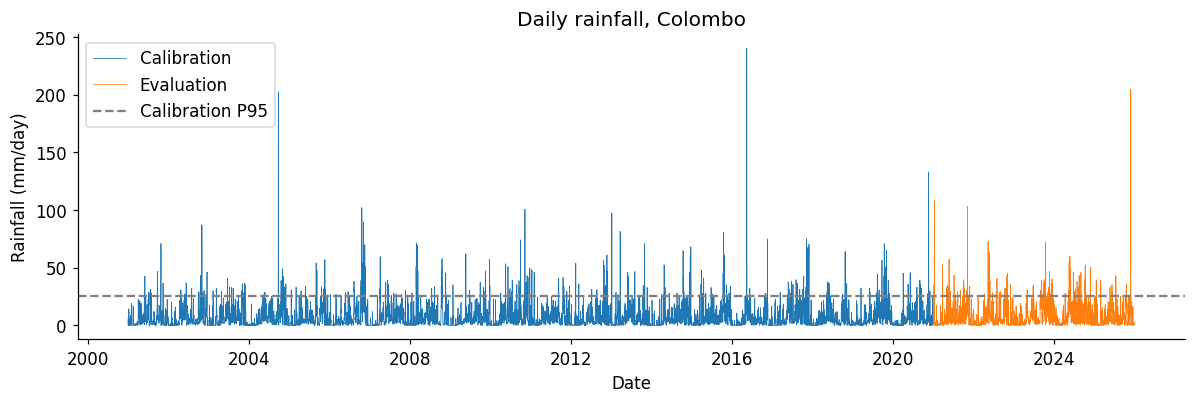

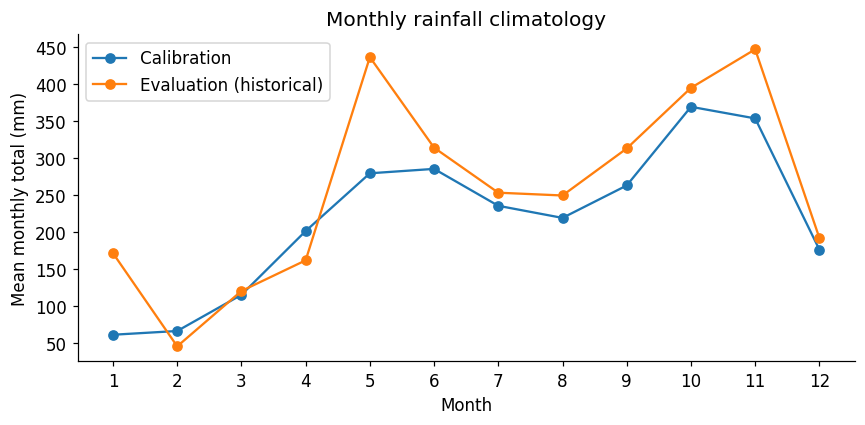

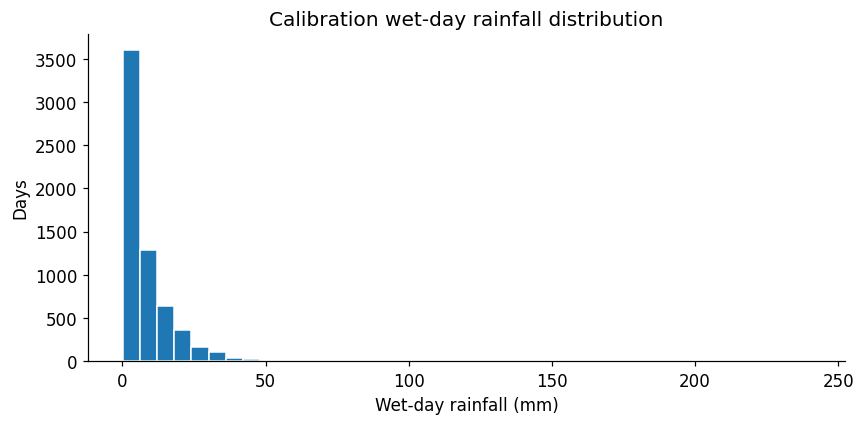

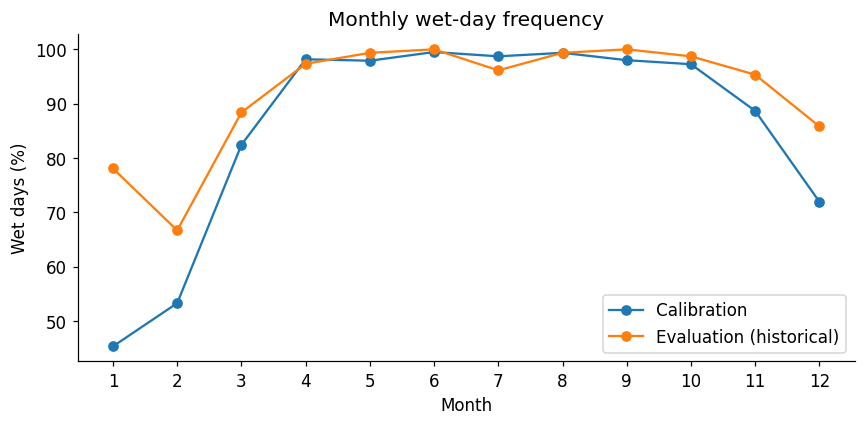

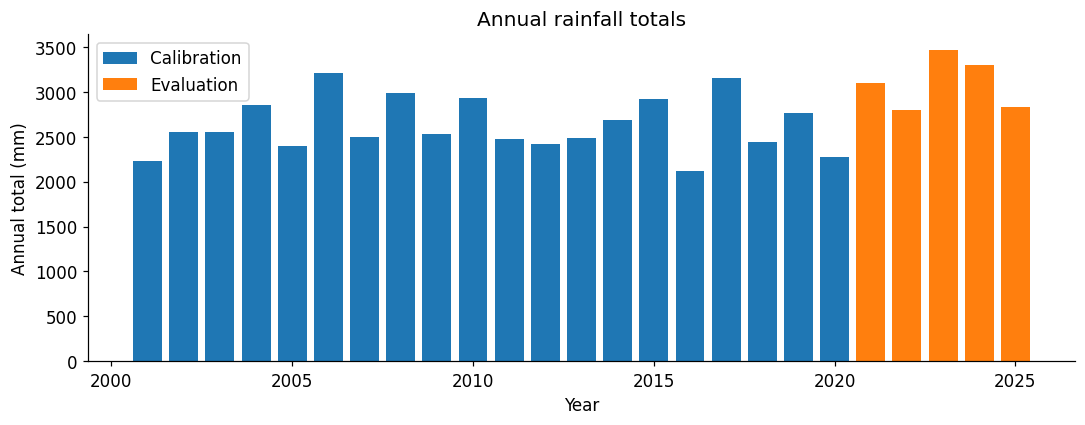

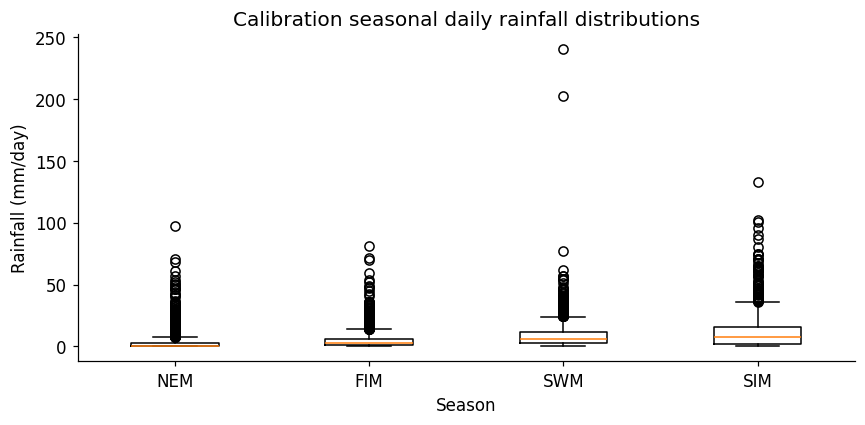

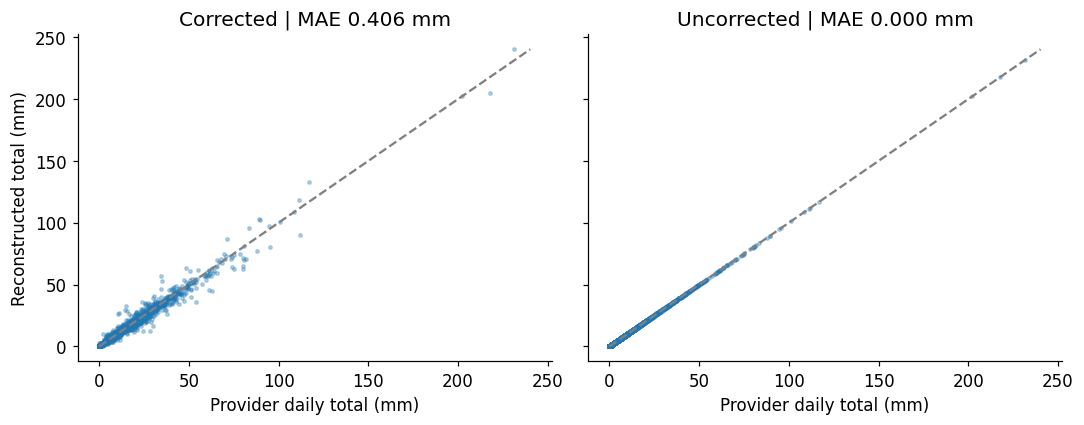

In [14]:
# C08
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
def finish(fig, name):
    fig.tight_layout(); fig.savefig(OUTPUT/'figures'/f'{name}.png',dpi=300,bbox_inches='tight'); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(11,3.8)); ax.plot(cal.date,cal.rainfall_mm,lw=.5,label='Calibration'); ax.plot(evaluation.date,evaluation.rainfall_mm,lw=.5,label='Evaluation'); ax.axhline(q95,ls='--',color='gray',label='Calibration P95'); ax.set(ylabel='Rainfall (mm/day)',xlabel='Date',title='Daily rainfall, Colombo'); ax.legend(); finish(fig,'F01_daily_rainfall')
fig,ax=plt.subplots(figsize=(8,4));
for part,label in [(cal,'Calibration'),(evaluation,'Evaluation (historical)')]:
    monthly=part.groupby(['year','month']).rainfall_mm.sum().groupby('month').mean(); ax.plot(monthly.index,monthly.values,marker='o',label=label)
ax.set(xticks=range(1,13),xlabel='Month',ylabel='Mean monthly total (mm)',title='Monthly rainfall climatology'); ax.legend(); finish(fig,'F02_monthly_climatology')
fig,ax=plt.subplots(figsize=(8,4)); ax.hist(cal.loc[cal.is_wet,'rainfall_mm'],bins=40,edgecolor='white'); ax.set(xlabel='Wet-day rainfall (mm)',ylabel='Days',title='Calibration wet-day rainfall distribution'); finish(fig,'F03_wet_day_histogram')
fig,ax=plt.subplots(figsize=(8,4));
for part,label in [(cal,'Calibration'),(evaluation,'Evaluation (historical)')]:
    s=part.groupby('month').is_wet.mean()*100; ax.plot(s.index,s.values,marker='o',label=label)
ax.set(xticks=range(1,13),xlabel='Month',ylabel='Wet days (%)',title='Monthly wet-day frequency'); ax.legend(); finish(fig,'F04_monthly_wet_frequency')
fig,ax=plt.subplots(figsize=(10,4));
for part,label in [(cal,'Calibration'),(evaluation,'Evaluation')]:
    s=part.groupby('year').rainfall_mm.sum(); ax.bar(s.index,s.values,label=label)
ax.set(xlabel='Year',ylabel='Annual total (mm)',title='Annual rainfall totals'); ax.legend(); finish(fig,'F05_annual_rainfall')
fig,ax=plt.subplots(figsize=(8,4)); seasons=['NEM','FIM','SWM','SIM']; ax.boxplot([cal.loc[cal.season==s,'rainfall_mm'] for s in seasons]); ax.set(xticks=range(1,5),xticklabels=seasons,ylabel='Rainfall (mm/day)',xlabel='Season',title='Calibration seasonal daily rainfall distributions'); finish(fig,'F06_seasonal_distributions')
fig,axs=plt.subplots(1,2,figsize=(10,4),sharex=True,sharey=True); limit=comparison[['reference','corrected','uncorrected']].max().max();
for ax,col in zip(axs,['corrected','uncorrected']):
    ax.scatter(comparison.reference,comparison[col],s=5,alpha=.3); ax.plot([0,limit],[0,limit],ls='--',color='gray'); ax.set(xlabel='Provider daily total (mm)',title=col.capitalize()+f" | MAE {metrics.loc[col,'MAE_mm']:.3f} mm")
axs[0].set_ylabel('Reconstructed total (mm)'); finish(fig,'F07_daily_aggregation_comparison')

## 6. Discussion and limitations

Daily provider totals are a comparison product, not independent rain-gauge observations. Differences can reflect accumulation boundaries, rounding or provider processing/model selection; residuals cannot identify the exact mechanism without acquisition metadata. The midnight identity isolates the effect of the timestamp convention. Best Match may introduce discontinuities. Historical holdout summaries are not forecast skill. Gamma fitting, distribution support, Markov order and simulation verification remain pending.

Local execution found the uncorrected totals match the supplied daily product to floating-point precision; corrected MAE 0.406067 mm, RMSE 1.303786 mm and maximum difference 22 mm. The verified midnight identity explains the differences. Retain the approved corrected series; revisit the accumulation convention only with documented evidence. Calibration P95 = 25.2 mm; P99 = 46.296 mm. No positive trace totals were removed. Figures and tables: modified Open-Meteo data, CC BY 4.0.

## 7. References

1. R. D. Stern and R. Coe, “A model fitting analysis of daily rainfall data,” Journal of the Royal Statistical Society: Series A, vol. 147, no. 1, pp. 1–34, 1984. https://academic.oup.com/jrsssa/article/147/1/1/7106047
   - Relevance: Seasonally varying occurrence and conditional rainfall amounts; dry-spell analysis.

2. D. S. Wilks, “Multisite generalization of a daily stochastic precipitation generation model,” Journal of Hydrology, vol. 210, pp. 178–191, 1998. https://doi.org/10.1016/S0022-1694(98)00186-3
   - Relevance: Mixed exponential amounts and spatial dependence; motivates comparison rather than adopting a multisite model.

3. S. Wilson Kemsley, T. J. Osborn, S. Dorling, C. Wallace, and J. Parker, “Selecting Markov chain orders for generating daily precipitation series across different Köppen climate regimes,” International Journal of Climatology, accepted manuscript, 2021. https://doi.org/10.1002/joc.7175
   - Relevance: Model-order performance depends on metric; tropical spell lengths merit particular attention.

4. S. Wilson Kemsley, T. J. Osborn, S. R. Dorling, and C. Wallace, “Pattern scaling the parameters of a Markov-chain gamma-distribution daily precipitation generator,” International Journal of Climatology, online 2023. https://doi.org/10.1002/joc.8320
   - Relevance: Monthly transition probabilities and gamma parameters; pattern scaling requires external climate information.

5. H. G. Jin, S. Hong, and Y. Kim, “Synthetic rainfall modeling using a modified hybrid gamma-GP distribution,” Applied Sciences, vol. 15, art. 9563, 2025. https://doi.org/10.3390/app15179563
   - Relevance: Hybrid body-tail modelling and seasonal variability; not evidence of local fit.

6. S. Sohrabi and F. P. Brissette, “Evaluation of a stochastic weather generator for long-term ensemble streamflow forecasts,” Hydrological Sciences Journal, vol. 66, no. 3, pp. 474–487, 2021. https://doi.org/10.1080/02626667.2021.1873343
   - Relevance: Ensemble evaluation against historical resampling; gamma tail limitations.

7. A. Deoras, A. G. Turner, K. M. R. Hunt, and I. M. S. P. Jayawardena, “The influence of weather patterns and the Madden-Julian Oscillation on extreme precipitation over Sri Lanka,” Geophysical Research Letters, vol. 50, e2023GL103727, 2023. https://doi.org/10.1029/2023GL103727
   - Relevance: Seasonality and persistence of extremes; national thresholds are not Colombo thresholds.

8. J. Muñoz-Sabater et al., “ERA5-Land: a state-of-the-art global reanalysis dataset for land applications,” Earth System Science Data, vol. 13, pp. 4349–4383, 2021. https://doi.org/10.5194/essd-13-4349-2021
   - Relevance: Reanalysis resolution and land-surface methodology; finer resolution does not guarantee local rainfall accuracy.

Dataset attribution is separate in `data/README.md`.